# 01 · Análisis exploratorio: denuncias del Ministerio Público (2022–2025)

**Proyecto:** Agrupamiento de municipios de Guatemala mediante algoritmos de aprendizaje no supervisado según la incidencia de doce delitos.

**Fuente:** Ministerio Público de Guatemala (MP), datos obtenidos mediante solicitud de acceso a la información pública.

## Objetivos del notebook

1. Comprender la estructura y la granularidad del conjunto de denuncias.
2. Validar la calidad de los datos (esquema, nulos, duplicados, dominios y cobertura).
3. Describir el comportamiento **temporal**, **por delito** y **territorial** de las denuncias.
4. Analizar la **distribución** de los conteos municipales de cada delito.
5. Generar una tabla limpia *municipio × año × delito* para integrarla con la población (notebook 03).

> **Alcance.** Este notebook analiza la fuente del MP por sí sola, en **conteos absolutos**. Los conteos todavía no son comparables entre municipios porque dependen del tamaño de la población; la comparación justa se hace con tasas en el notebook `03_EDA_integrado`.

## 0. Configuración

In [1]:
import sys
from pathlib import Path

# Ubica la raíz del proyecto (la carpeta que contiene "data" y "src").
RAIZ = Path.cwd().resolve()
while not (RAIZ / "src").exists() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

from src.utilidades import (
    ARCHIVO_DENUNCIAS, RUTA_PROCESSED, ANIOS_ESTUDIO, MESES_ORDEN, NUMERO_MES,
    DELITOS, ORDEN_DELITOS, NOMBRE_CORTO, FAMILIA_DELITO, COLOR, COLOR_FAMILIA,
    CMAP_SECUENCIAL, CMAP_DIVERGENTE, configurar_estilo, subtitulo, fuente,
    guardar_figura, formato_miles, coeficiente_gini, curva_lorenz,
    resumen_distribucion,
)

configurar_estilo()
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

CARPETA_FIG = "01_denuncias"
FUENTE_MP = "Fuente: elaboración propia con datos del Ministerio Público (2022–2025)."

## 1. Carga de datos

In [2]:
df_original = pd.read_csv(ARCHIVO_DENUNCIAS, encoding="utf-8-sig")
df = df_original.copy()

print(f"Archivo: {ARCHIVO_DENUNCIAS.name}")
print(f"Dimensiones: {df.shape[0]:,} filas × {df.shape[1]} columnas")
display(df.head())

Archivo: denuncias_2022_2025.csv
Dimensiones: 75,973 filas × 7 columnas


,Departamento,Municipio,Anio,Mes,Grado_Delito,Delito,Denuncias
0,Alta Verapaz,Chahal,2022,abr,Consumado,Agresión sexual,1.00
1,Alta Verapaz,Chahal,2022,oct,Tentativa,Agresión sexual,1.00
2,Alta Verapaz,Chisec,2022,feb,Consumado,Agresión sexual,1.00
3,Alta Verapaz,Chisec,2022,mar,Consumado,Agresión sexual,1.00
4,Alta Verapaz,Chisec,2022,mar,Tentativa,Agresión sexual,1.00


### Diccionario de datos

| Variable | Tipo | Descripción |
|---|---|---|
| `Departamento` | Texto | Departamento de Guatemala donde se registró la denuncia (22). |
| `Municipio` | Texto | Municipio donde se registró la denuncia. |
| `Anio` | Entero | Año del registro (2022–2025). |
| `Mes` | Texto | Mes abreviado (`ene` … `dic`). |
| `Grado_Delito` | Texto | Forma de realización: *Consumado*, *Tentativa* o *Continuado*. |
| `Delito` | Texto | Uno de los 12 delitos del estudio. |
| `Denuncias` | Numérico | Cantidad de denuncias de esa combinación. |

**Unidad de observación:** cada fila es una combinación *departamento – municipio – año – mes – grado – delito* con **al menos una** denuncia. Las combinaciones con cero denuncias **no aparecen** en el archivo; esto es clave para interpretar los estadísticos más adelante.

## 2. Validación de calidad

### 2.1 Esquema, tipos, nulos y duplicados

In [3]:
COLUMNAS_ESPERADAS = ["Departamento", "Municipio", "Anio", "Mes",
                      "Grado_Delito", "Delito", "Denuncias"]
LLAVE = ["Departamento", "Municipio", "Anio", "Mes", "Grado_Delito", "Delito"]

perfil = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "no_nulos": df.notna().sum(),
    "nulos": df.isna().sum(),
    "valores_unicos": df.nunique(dropna=False),
})
display(perfil)

validaciones = pd.Series({
    "Columnas esperadas presentes": set(COLUMNAS_ESPERADAS) == set(df.columns),
    "Filas duplicadas exactas": int(df.duplicated().sum()),
    "Filas con llave duplicada": int(df.duplicated(subset=LLAVE).sum()),
    "Valores nulos": int(df.isna().sum().sum()),
    "Textos con espacios extremos": int(sum(
        (df[c].astype(str) != df[c].astype(str).str.strip()).sum()
        for c in ["Departamento", "Municipio", "Mes", "Grado_Delito", "Delito"])),
}, name="resultado")
display(validaciones.to_frame())

,tipo,no_nulos,nulos,valores_unicos
Departamento,str,75973,0,22
Municipio,str,75973,0,334
Anio,int64,75973,0,4
Mes,str,75973,0,12
Grado_Delito,str,75973,0,3
Delito,str,75973,0,12
Denuncias,float64,75973,0,369


,resultado
Columnas esperadas presentes,True
Filas duplicadas exactas,0
Filas con llave duplicada,0
Valores nulos,0
Textos con espacios extremos,0


### 2.2 Dominio de la variable `Denuncias`

Se verifica que sea un conteo válido: entero, positivo y sin ceros (porque el archivo solo trae combinaciones observadas).

In [4]:
dominio = pd.Series({
    "mínimo": df["Denuncias"].min(),
    "máximo": df["Denuncias"].max(),
    "negativos": int((df["Denuncias"] < 0).sum()),
    "ceros": int((df["Denuncias"] == 0).sum()),
    "no enteros": int((df["Denuncias"] % 1 != 0).sum()),
}, name="resultado")
display(dominio.to_frame())

,resultado
mínimo,1.00
máximo,"1,372.00"
negativos,0.00
ceros,0.00
no enteros,0.00


### 2.3 Dominio de las variables categóricas

In [5]:
dominio_cat = pd.Series({
    "Años": sorted(df["Anio"].unique().tolist()),
    "Meses presentes": int(df["Mes"].nunique()),
    "Meses fuera del catálogo": sorted(set(df["Mes"]) - set(MESES_ORDEN)),
    "Departamentos": int(df["Departamento"].nunique()),
    "Nombres de municipio distintos": int(df["Municipio"].nunique()),
    "Pares departamento–municipio": int(df[["Departamento", "Municipio"]].drop_duplicates().shape[0]),
    "Grados del delito": sorted(df["Grado_Delito"].unique().tolist()),
    "Delitos": int(df["Delito"].nunique()),
    "Delitos fuera del catálogo del estudio": sorted(set(df["Delito"]) - set(DELITOS)),
}, name="valor")
display(dominio_cat.to_frame())

,valor
Años,"[2022, 2023, 2024, 2025]"
Meses presentes,12
Meses fuera del catálogo,[]
Departamentos,22
Nombres de municipio distintos,334
Pares departamento–municipio,340
Grados del delito,"[Consumado, Continuado, Tentativa]"
Delitos,12
Delitos fuera del catálogo del estudio,[]


El archivo cubre los **340 municipios** del país (22 departamentos), los **48 meses** de 2022 a 2025 y exactamente los **12 delitos** del estudio. Hay 334 nombres de municipio distintos pero 340 pares departamento–municipio: existen **municipios homónimos** en departamentos diferentes.

In [6]:
homonimos = (
    df[["Departamento", "Municipio"]].drop_duplicates()
    .groupby("Municipio")["Departamento"].agg(lambda s: ", ".join(sorted(s)))
)
homonimos = homonimos[homonimos.str.contains(",")].to_frame("Departamentos")
display(homonimos)

,Departamentos
Municipio,
La Democracia,"Escuintla, Huehuetenango"
La Libertad,"Huehuetenango, Petén"
San José,"Escuintla, Petén"
San Lorenzo,"San Marcos, Suchitepéquez"
San Pedro Sacatepéquez,"Guatemala, San Marcos"
Santa Bárbara,"Huehuetenango, Suchitepéquez"


Por eso **el nombre del municipio no es una llave suficiente**. En adelante se usa el identificador compuesto `Municipio_ID = "Departamento | Municipio"`.

### 2.4 Cobertura municipio–año

Se revisa si algún municipio no registra ninguna denuncia en algún año completo, lo que podría indicar un problema de registro.

In [7]:
pares = df[["Departamento", "Municipio"]].drop_duplicates()
cobertura = (
    pares.merge(pd.DataFrame({"Anio": ANIOS_ESTUDIO}), how="cross")
    .merge(df[["Departamento", "Municipio", "Anio"]].drop_duplicates(),
           how="left", indicator=True)
)
sin_registro = cobertura.query("_merge == 'left_only'").drop(columns="_merge")
print(f"Combinaciones municipio–año sin ninguna denuncia: {len(sin_registro)}")
display(sin_registro)

Combinaciones municipio–año sin ninguna denuncia: 1


,Departamento,Municipio,Anio
1188,Sololá,Concepción,2022


In [8]:
detalle = (df.query("Departamento == 'Sololá' and Municipio == 'Concepción'")
             .groupby("Anio")["Denuncias"].sum())
display(detalle.to_frame("Denuncias"))

,Denuncias
Anio,
2023,3.00
2024,3.00
2025,5.00


**Sololá | Concepción** no tiene denuncias en 2022 y muy pocas en los años siguientes. Es un municipio pequeño, así que un año sin denuncias es plausible y se trata como **cero real**, no como dato faltante. Se deja documentado como observación.

## 3. Preparación

1. Tipos correctos y orden cronológico del mes.
2. Identificador territorial `Municipio_ID`.
3. **Suma de los grados del delito** (consumado + tentativa + continuado): el estudio mide la incidencia total de cada delito.
4. **Cuadrícula completa** *municipio × año × mes × delito* rellenando con **cero** las combinaciones ausentes. Sin este paso, cualquier promedio o desviación ignoraría los meses sin denuncias y quedaría sesgado hacia arriba.

In [9]:
df["Anio"] = df["Anio"].astype(int)
df["Denuncias"] = df["Denuncias"].astype(int)
df["Municipio_ID"] = df["Departamento"] + " | " + df["Municipio"]

# Suma de grados del delito
mensual_obs = (df.groupby(["Departamento", "Municipio", "Municipio_ID",
                           "Anio", "Mes", "Delito"], as_index=False)["Denuncias"].sum())

# Cuadrícula completa
territorios = df[["Departamento", "Municipio", "Municipio_ID"]].drop_duplicates()
cuadricula = (territorios
              .merge(pd.DataFrame({"Anio": ANIOS_ESTUDIO}), how="cross")
              .merge(pd.DataFrame({"Mes": MESES_ORDEN}), how="cross")
              .merge(pd.DataFrame({"Delito": ORDEN_DELITOS}), how="cross"))

mensual = cuadricula.merge(mensual_obs, how="left",
                           on=["Departamento", "Municipio", "Municipio_ID", "Anio", "Mes", "Delito"])
mensual["Denuncias"] = mensual["Denuncias"].fillna(0).astype(int)
mensual["Fecha"] = pd.to_datetime(dict(year=mensual["Anio"],
                                       month=mensual["Mes"].map(NUMERO_MES), day=1))

print(f"Filas observadas (grados sumados): {len(mensual_obs):,}")
print(f"Filas de la cuadrícula completa:   {len(mensual):,}  (340 × 4 × 12 × 12)")
print(f"Combinaciones con cero denuncias:  {(mensual['Denuncias'] == 0).sum():,} "
      f"({(mensual['Denuncias'] == 0).mean():.1%})")
print(f"¿Se conserva el total de denuncias? {mensual['Denuncias'].sum() == df['Denuncias'].sum()}")

Filas observadas (grados sumados): 67,797
Filas de la cuadrícula completa:   195,840  (340 × 4 × 12 × 12)
Combinaciones con cero denuncias:  128,043 (65.4%)
¿Se conserva el total de denuncias? True


Dos de cada tres combinaciones *municipio–mes–delito* tienen **cero** denuncias: los datos son **dispersos** (muchos ceros), algo que se debe tomar en cuenta al construir indicadores.

## 4. Panorama general

In [10]:
total = df["Denuncias"].sum()
panorama = pd.Series({
    "Denuncias totales 2022–2025": f"{total:,}",
    "Promedio anual": f"{total / 4:,.0f}",
    "Promedio mensual": f"{total / 48:,.0f}",
    "Municipios": territorios.shape[0],
    "Delitos": df["Delito"].nunique(),
}, name="valor")
display(panorama.to_frame())

,valor
Denuncias totales 2022–2025,"435,043"
Promedio anual,"108,761"
Promedio mensual,"9,063"
Municipios,340
Delitos,12


## 5. Comportamiento temporal

### 5.1 Serie mensual

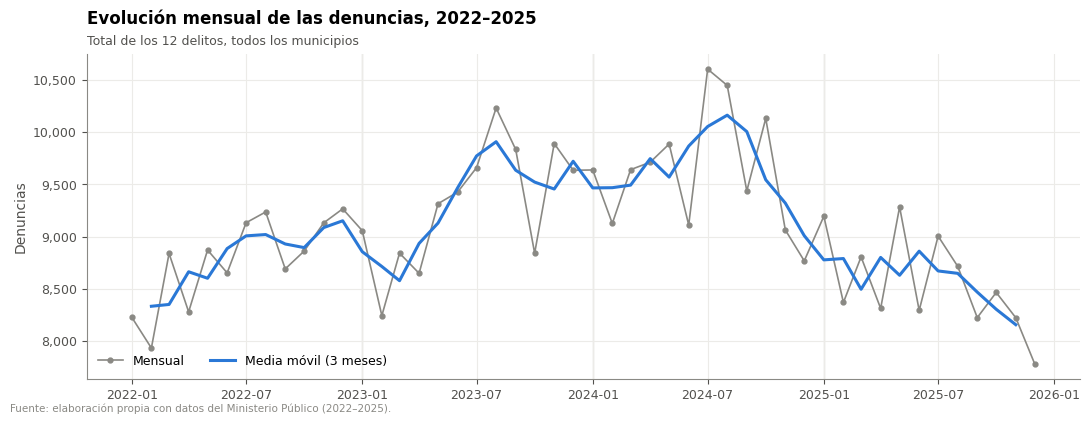

In [11]:
serie_mensual = mensual.groupby("Fecha")["Denuncias"].sum()
media_movil = serie_mensual.rolling(3, center=True).mean()

fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(serie_mensual.index, serie_mensual.values, color=COLOR["gris"],
        linewidth=1.2, marker="o", markersize=3.5, label="Mensual")
ax.plot(media_movil.index, media_movil.values, color=COLOR["azul"],
        linewidth=2.2, label="Media móvil (3 meses)")
for anio in ANIOS_ESTUDIO[1:]:
    ax.axvline(pd.Timestamp(f"{anio}-01-01"), color=COLOR["gris_claro"], linewidth=1, zorder=0)
ax.set_title("Evolución mensual de las denuncias, 2022–2025")
subtitulo(ax, "Total de los 12 delitos, todos los municipios")
ax.set_ylabel("Denuncias")
formato_miles(ax, "y")
ax.legend(loc="lower left", ncol=2)
fuente(fig, FUENTE_MP)
fig.tight_layout()
guardar_figura(fig, "01_serie_mensual", CARPETA_FIG)
plt.show()

### 5.2 Totales anuales y estacionalidad

,Denuncias,Variación anual (%)
Anio,,
2022,105138,NaN
2023,111637,6.18
2024,115576,3.53
2025,102692,-11.15


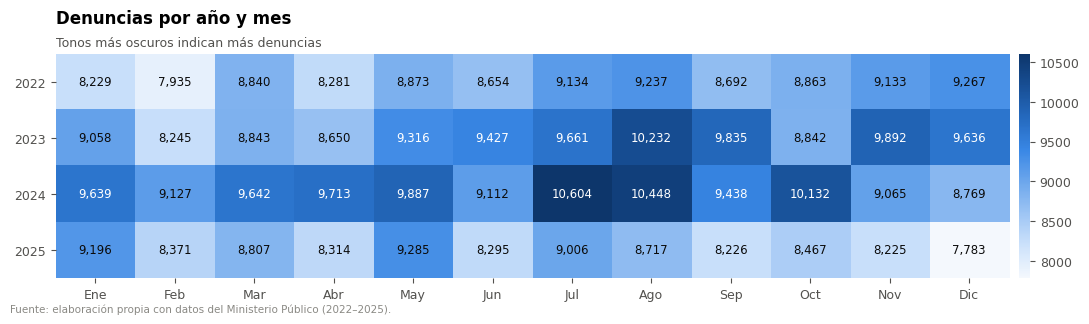

In [12]:
anual = mensual.groupby("Anio")["Denuncias"].sum()
anual_tabla = pd.DataFrame({"Denuncias": anual,
                            "Variación anual (%)": anual.pct_change() * 100})
display(anual_tabla)

tabla_anio_mes = (mensual.pivot_table(index="Anio", columns="Mes", values="Denuncias",
                                      aggfunc="sum").reindex(columns=MESES_ORDEN))

fig, ax = plt.subplots(figsize=(11, 3.2))
im = ax.imshow(tabla_anio_mes.values, cmap=CMAP_SECUENCIAL, aspect="auto")
ax.set_xticks(range(12), [m.capitalize() for m in MESES_ORDEN])
ax.set_yticks(range(4), tabla_anio_mes.index)
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
umbral = np.nanpercentile(tabla_anio_mes.values, 70)
for i in range(tabla_anio_mes.shape[0]):
    for j in range(12):
        v = tabla_anio_mes.values[i, j]
        ax.text(j, i, f"{v:,.0f}", ha="center", va="center", fontsize=8.5,
                color="white" if v > umbral else COLOR["texto"])
ax.set_title("Denuncias por año y mes")
subtitulo(ax, "Tonos más oscuros indican más denuncias")
fig.colorbar(im, ax=ax, fraction=0.025, pad=0.01).outline.set_visible(False)
fuente(fig, FUENTE_MP)
fig.tight_layout()
guardar_figura(fig, "02_heatmap_anio_mes", CARPETA_FIG)
plt.show()

### 5.3 Tendencia de cada delito

Para comparar delitos de magnitudes muy distintas se usa un **índice con base 2022 = 100**: valores mayores a 100 indican crecimiento respecto a 2022.

Anio,2022,2023,2024,2025,Total,Var. 2022–2025 (%)
Delito,,,,,,
Hurto,24659,30925,32593,25013,113190,1.44
Extorsión,14928,18416,24714,26539,84597,77.78
Robo agravado,18197,17630,15317,14356,65500,-21.11
Hurto agravado,15841,16779,15443,13776,61839,-13.04
Robo,18066,15570,16103,11937,61676,-33.93
Violación,5500,4668,4039,3723,17930,-32.31
Homicidio,3470,3467,3350,3525,13812,1.59
Agresión sexual,2571,2282,2180,1961,8994,-23.73
Asesinato,814,827,821,970,3432,19.16


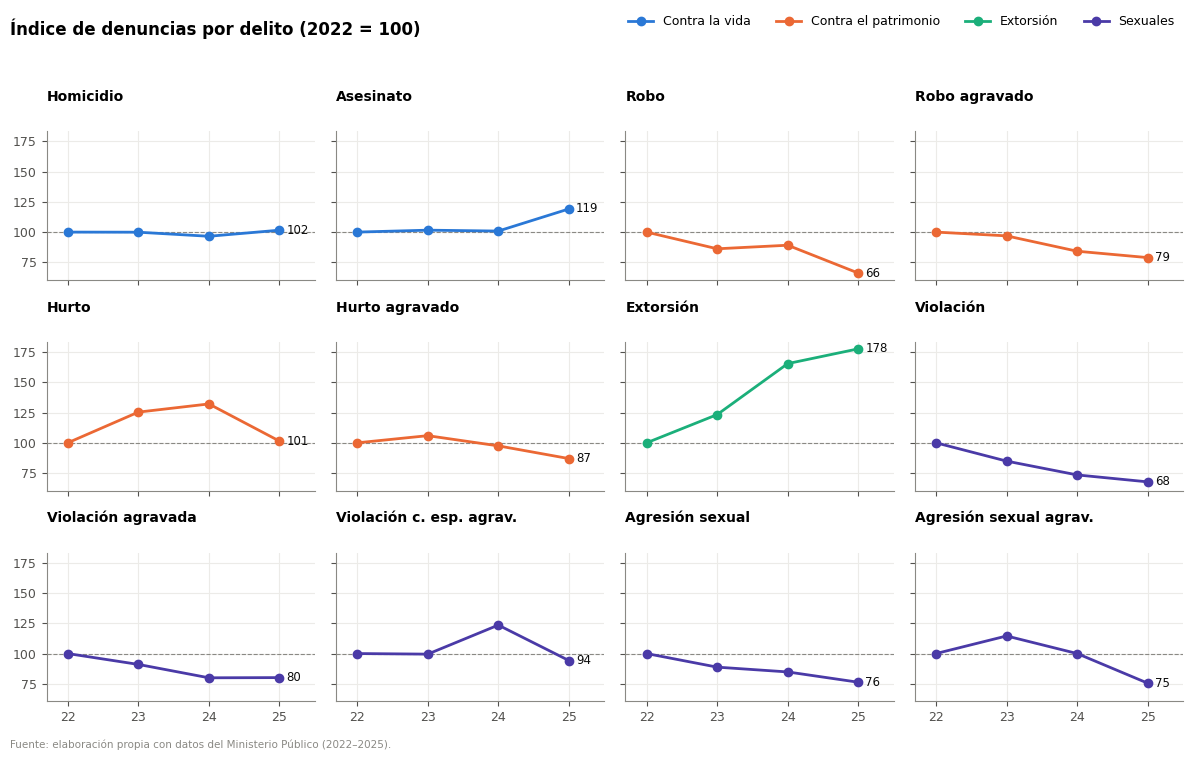

In [13]:
delito_anio = mensual.pivot_table(index="Delito", columns="Anio", values="Denuncias", aggfunc="sum")
delito_anio = delito_anio.reindex(ORDEN_DELITOS)
indice = delito_anio.div(delito_anio[2022], axis=0) * 100

tabla_delito_anio = delito_anio.copy()
tabla_delito_anio["Total"] = delito_anio.sum(axis=1)
tabla_delito_anio["Var. 2022–2025 (%)"] = (delito_anio[2025] / delito_anio[2022] - 1) * 100
display(tabla_delito_anio.sort_values("Total", ascending=False))

fig, axes = plt.subplots(3, 4, figsize=(12, 7.5), sharex=True, sharey=True)
for ax, delito in zip(axes.flat, ORDEN_DELITOS):
    color = COLOR_FAMILIA[FAMILIA_DELITO[delito]]
    ax.axhline(100, color=COLOR["gris"], linewidth=0.8, linestyle="--")
    ax.plot(ANIOS_ESTUDIO, indice.loc[delito], color=color, marker="o")
    final = indice.loc[delito, 2025]
    ax.text(2025.1, final, f"{final:.0f}", va="center", fontsize=8.5, color=COLOR["texto"])
    ax.set_title(NOMBRE_CORTO[delito], fontsize=10)
    ax.set_xticks(ANIOS_ESTUDIO, [str(a)[2:] for a in ANIOS_ESTUDIO])
    ax.set_xlim(2021.7, 2025.5)
fig.suptitle("Índice de denuncias por delito (2022 = 100)", x=0.01, ha="left",
             fontweight="bold", fontsize=12)
handles = [plt.Line2D([], [], color=c, marker="o", label=f) for f, c in COLOR_FAMILIA.items()]
fig.legend(handles=handles, loc="upper right", ncol=4, bbox_to_anchor=(0.99, 1.0))
fuente(fig, FUENTE_MP)
fig.tight_layout(rect=(0, 0.02, 1, 0.95))
guardar_figura(fig, "03_indice_por_delito", CARPETA_FIG)
plt.show()

## 6. Análisis por delito

### 6.1 Volumen y participación

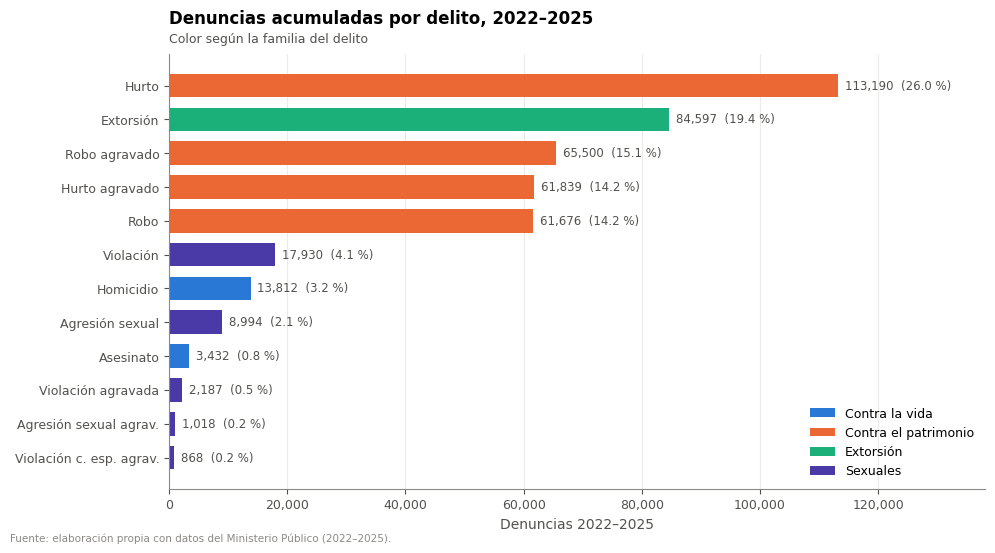

In [14]:
por_delito = (mensual.groupby("Delito")["Denuncias"].sum()
              .sort_values(ascending=True))
participacion = por_delito / por_delito.sum() * 100

fig, ax = plt.subplots(figsize=(10, 5.5))
colores = [COLOR_FAMILIA[FAMILIA_DELITO[d]] for d in por_delito.index]
ax.barh([NOMBRE_CORTO[d] for d in por_delito.index], por_delito.values,
        color=colores, height=0.7)
for i, (v, p) in enumerate(zip(por_delito.values, participacion.values)):
    ax.text(v + por_delito.max() * 0.01, i, f"{v:,.0f}  ({p:.1f} %)",
            va="center", fontsize=8.5, color=COLOR["texto_sec"])
ax.set_xlim(0, por_delito.max() * 1.22)
ax.grid(axis="y", visible=False)
formato_miles(ax, "x")
ax.set_xlabel("Denuncias 2022–2025")
ax.set_title("Denuncias acumuladas por delito, 2022–2025")
subtitulo(ax, "Color según la familia del delito")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in COLOR_FAMILIA.values()]
ax.legend(handles, COLOR_FAMILIA.keys(), loc="lower right")
fuente(fig, FUENTE_MP)
fig.tight_layout()
guardar_figura(fig, "04_denuncias_por_delito", CARPETA_FIG)
plt.show()

### 6.2 Grado del delito

El grado (consumado, tentativa, continuado) no será variable del modelo, pero conviene conocer su peso para justificar la decisión de **sumarlos**.

Grado_Delito,Consumado,Continuado,Tentativa
Delito,,,
Homicidio,78.40,0.20,21.40
Asesinato,82.80,0.20,17.00
Robo,98.30,0.20,1.50
Robo agravado,98.60,0.10,1.30
Hurto,99.10,0.30,0.60
Hurto agravado,99.20,0.30,0.60
Extorsión,73.00,0.60,26.30
Violación,97.00,0.70,2.30
Violación agravada,97.90,1.20,0.90


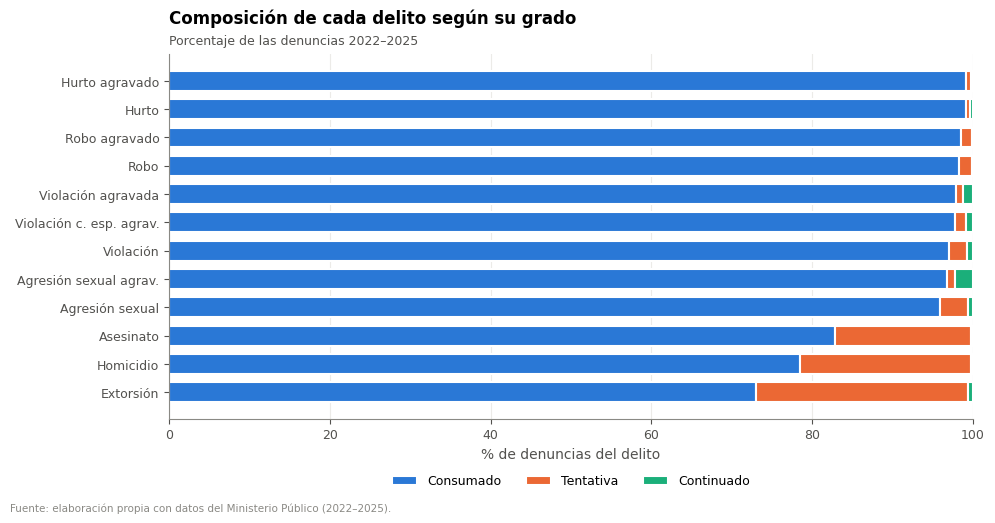

In [15]:
grado = (df.pivot_table(index="Delito", columns="Grado_Delito", values="Denuncias",
                        aggfunc="sum", fill_value=0)
           .reindex(ORDEN_DELITOS))
grado_pct = grado.div(grado.sum(axis=1), axis=0) * 100
display(grado_pct.round(1))

grado_pct = grado_pct.sort_values("Consumado")
fig, ax = plt.subplots(figsize=(10, 5.2))
izquierda = np.zeros(len(grado_pct))
colores_grado = {"Consumado": COLOR["azul"], "Tentativa": COLOR["naranja"],
                 "Continuado": COLOR["aqua"]}
for g in ["Consumado", "Tentativa", "Continuado"]:
    ax.barh([NOMBRE_CORTO[d] for d in grado_pct.index], grado_pct[g], left=izquierda,
            color=colores_grado[g], label=g, height=0.7, edgecolor="white", linewidth=1.5)
    izquierda += grado_pct[g].values
ax.set_xlim(0, 100)
ax.set_xlabel("% de denuncias del delito")
ax.grid(axis="y", visible=False)
ax.set_title("Composición de cada delito según su grado")
subtitulo(ax, "Porcentaje de las denuncias 2022–2025")
ax.legend(ncol=3, loc="lower center", bbox_to_anchor=(0.5, -0.22))
fuente(fig, FUENTE_MP)
fig.tight_layout()
guardar_figura(fig, "05_grado_por_delito", CARPETA_FIG)
plt.show()

## 7. Análisis territorial (conteos absolutos)

> Los conteos absolutos reflejan **dónde se denuncia más**, no **dónde el riesgo relativo es mayor**: los municipios más poblados acumulan más denuncias por simple tamaño. Este apartado sirve para describir la fuente y medir la concentración.

### 7.1 Por departamento

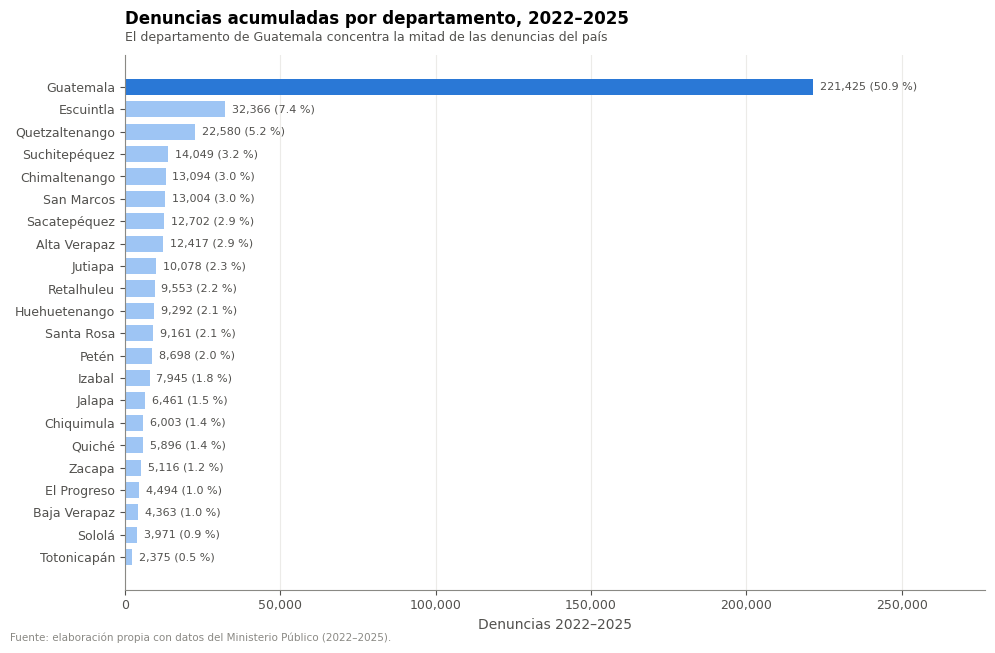

In [16]:
por_depto = mensual.groupby("Departamento")["Denuncias"].sum().sort_values()
pct_depto = por_depto / por_depto.sum() * 100

fig, ax = plt.subplots(figsize=(10, 6.5))
colores = [COLOR["azul"] if d == "Guatemala" else "#9ec5f4" for d in por_depto.index]
ax.barh(por_depto.index, por_depto.values, color=colores, height=0.72)
for i, (v, p) in enumerate(zip(por_depto.values, pct_depto.values)):
    ax.text(v + por_depto.max() * 0.01, i, f"{v:,.0f} ({p:.1f} %)", va="center",
            fontsize=8, color=COLOR["texto_sec"])
ax.set_xlim(0, por_depto.max() * 1.25)
ax.grid(axis="y", visible=False)
formato_miles(ax, "x")
ax.set_xlabel("Denuncias 2022–2025")
ax.set_title("Denuncias acumuladas por departamento, 2022–2025")
subtitulo(ax, "El departamento de Guatemala concentra la mitad de las denuncias del país")
fuente(fig, FUENTE_MP)
fig.tight_layout()
guardar_figura(fig, "06_denuncias_por_departamento", CARPETA_FIG)
plt.show()

### 7.2 Municipios con más denuncias

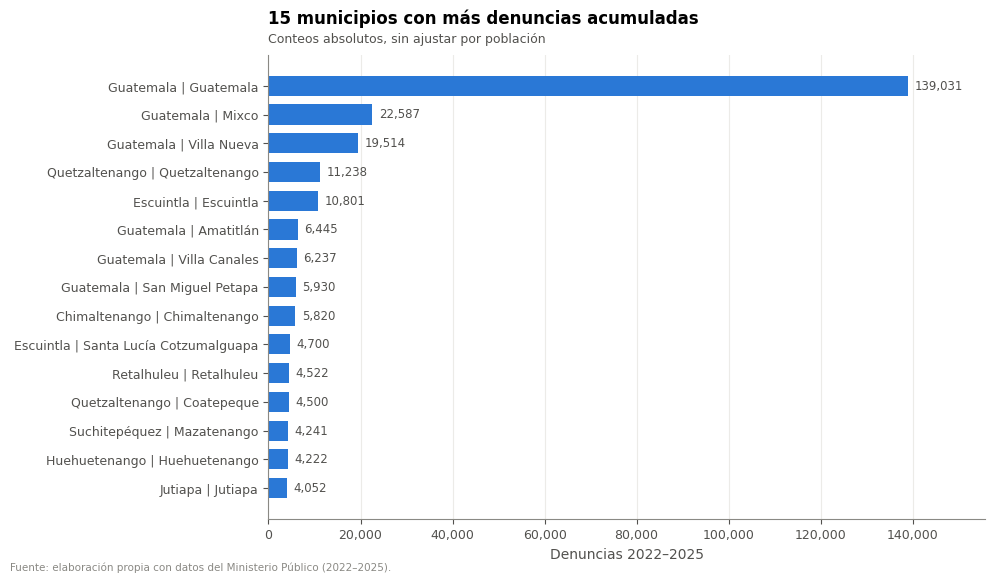

In [17]:
por_mun = mensual.groupby("Municipio_ID")["Denuncias"].sum().sort_values(ascending=False)
top = por_mun.head(15).sort_values()

fig, ax = plt.subplots(figsize=(10, 5.8))
ax.barh(top.index, top.values, color=COLOR["azul"], height=0.7)
for i, v in enumerate(top.values):
    ax.text(v + top.max() * 0.01, i, f"{v:,.0f}", va="center", fontsize=8.5,
            color=COLOR["texto_sec"])
ax.set_xlim(0, top.max() * 1.12)
ax.grid(axis="y", visible=False)
formato_miles(ax, "x")
ax.set_xlabel("Denuncias 2022–2025")
ax.set_title("15 municipios con más denuncias acumuladas")
subtitulo(ax, "Conteos absolutos, sin ajustar por población")
fuente(fig, FUENTE_MP)
fig.tight_layout()
guardar_figura(fig, "07_top15_municipios", CARPETA_FIG)
plt.show()

### 7.3 Concentración territorial: curva de Lorenz e índice de Gini

La **curva de Lorenz** muestra qué proporción de las denuncias acumula cada proporción de municipios (ordenados de menor a mayor). Si todos tuvieran las mismas denuncias, la curva coincidiría con la diagonal. El **índice de Gini** resume esa distancia: 0 = reparto igual, 1 = todo en un solo municipio.

Índice de Gini (total de denuncias por municipio): 0.774
El municipio con más denuncias (Guatemala | Guatemala) concentra el 32.0 %
Los 10 municipios con más denuncias concentran el 53.4 %


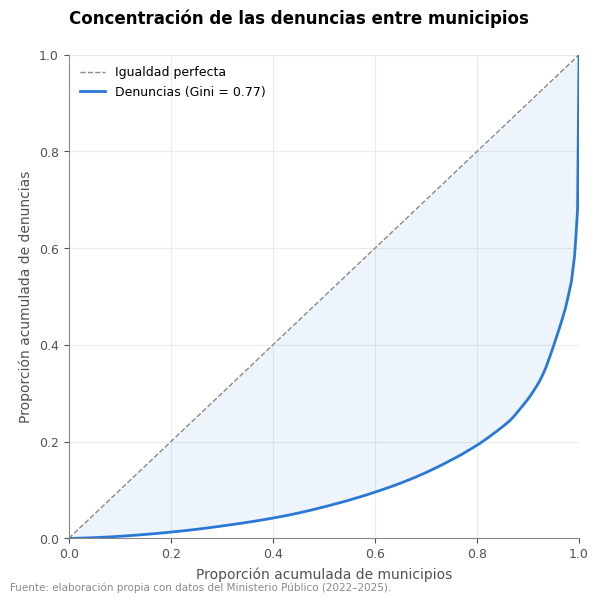

In [18]:
gini_total = coeficiente_gini(por_mun.values)
x_l, y_l = curva_lorenz(por_mun.values)
top10_pct = por_mun.head(10).sum() / por_mun.sum() * 100
top1_pct = por_mun.iloc[0] / por_mun.sum() * 100

print(f"Índice de Gini (total de denuncias por municipio): {gini_total:.3f}")
print(f"El municipio con más denuncias ({por_mun.index[0]}) concentra el {top1_pct:.1f} %")
print(f"Los 10 municipios con más denuncias concentran el {top10_pct:.1f} %")

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot([0, 1], [0, 1], color=COLOR["gris"], linestyle="--", linewidth=1, label="Igualdad perfecta")
ax.plot(x_l, y_l, color=COLOR["azul"], label=f"Denuncias (Gini = {gini_total:.2f})")
ax.fill_between(x_l, y_l, x_l, color=COLOR["azul"], alpha=0.08)
ax.set_xlabel("Proporción acumulada de municipios")
ax.set_ylabel("Proporción acumulada de denuncias")
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.set_title("Concentración de las denuncias entre municipios")
ax.legend(loc="upper left")
fuente(fig, FUENTE_MP)
fig.tight_layout()
guardar_figura(fig, "08_lorenz_denuncias", CARPETA_FIG)
plt.show()

In [19]:
# Gini por delito: ¿todos los delitos están igual de concentrados?
mun_delito = mensual.pivot_table(index="Municipio_ID", columns="Delito",
                                 values="Denuncias", aggfunc="sum")[ORDEN_DELITOS]
gini_delito = mun_delito.apply(coeficiente_gini).sort_values(ascending=False)
display(gini_delito.rename(index=NOMBRE_CORTO).to_frame("Gini"))

,Gini
Delito,
Robo,0.88
Robo agravado,0.86
Asesinato,0.83
Hurto,0.80
Hurto agravado,0.80
Agresión sexual agrav.,0.79
Homicidio,0.76
Extorsión,0.76
Violación c. esp. agrav.,0.72


## 8. Distribución de los conteos municipales por delito

Aquí cada observación es un **municipio** (340) y la variable es el total de denuncias 2022–2025 de cada delito, que es la forma que tendrá la matriz del agrupamiento. Se analizan:

- **Asimetría** (*skewness*): 0 = simétrica; > 1 = cola larga a la derecha.
- **Curtosis** (exceso): 0 = como la normal; valores altos = colas pesadas y valores extremos.
- **CV** (coeficiente de variación = desviación / media): dispersión relativa.
- **% de ceros**: municipios sin ninguna denuncia del delito en los 4 años.

In [20]:
resumen_conteos = resumen_distribucion(mun_delito).rename(index=NOMBRE_CORTO)
display(resumen_conteos.round(2))

,media,mediana,desv_est,CV,min,Q1,Q3,max,asimetria,curtosis,pct_ceros
Homicidio,40.62,11.00,160.60,3.95,0.00,4.00,28.00,"2,723.00",14.11,228.33,6.18
Asesinato,10.09,2.00,53.28,5.28,0.00,0.00,6.00,875.00,13.61,207.68,27.94
Robo,181.40,22.50,"1,685.39",9.29,0.00,10.75,63.50,"30,695.00",17.57,314.95,0.29
Robo agravado,192.65,28.00,"1,349.93",7.01,0.00,8.00,79.25,"24,018.00",16.39,284.43,1.18
Hurto,332.91,73.50,"2,205.61",6.63,2.00,36.75,168.00,"39,559.00",16.73,293.24,0.00
Hurto agravado,181.88,40.00,"1,039.56",5.72,0.00,16.00,109.00,"18,466.00",16.22,280.50,0.29
Extorsión,248.81,74.50,"1,128.02",4.53,0.00,27.00,171.25,"19,298.00",14.64,239.19,0.29
Violación,52.74,29.00,106.53,2.02,1.00,14.00,56.25,"1,677.00",10.99,158.42,0.00
Violación agravada,6.43,3.00,10.43,1.62,0.00,1.00,7.00,130.00,6.34,62.31,11.47
Violación c. esp. agrav.,2.55,1.00,6.37,2.50,0.00,0.00,3.00,85.00,8.34,91.32,36.76


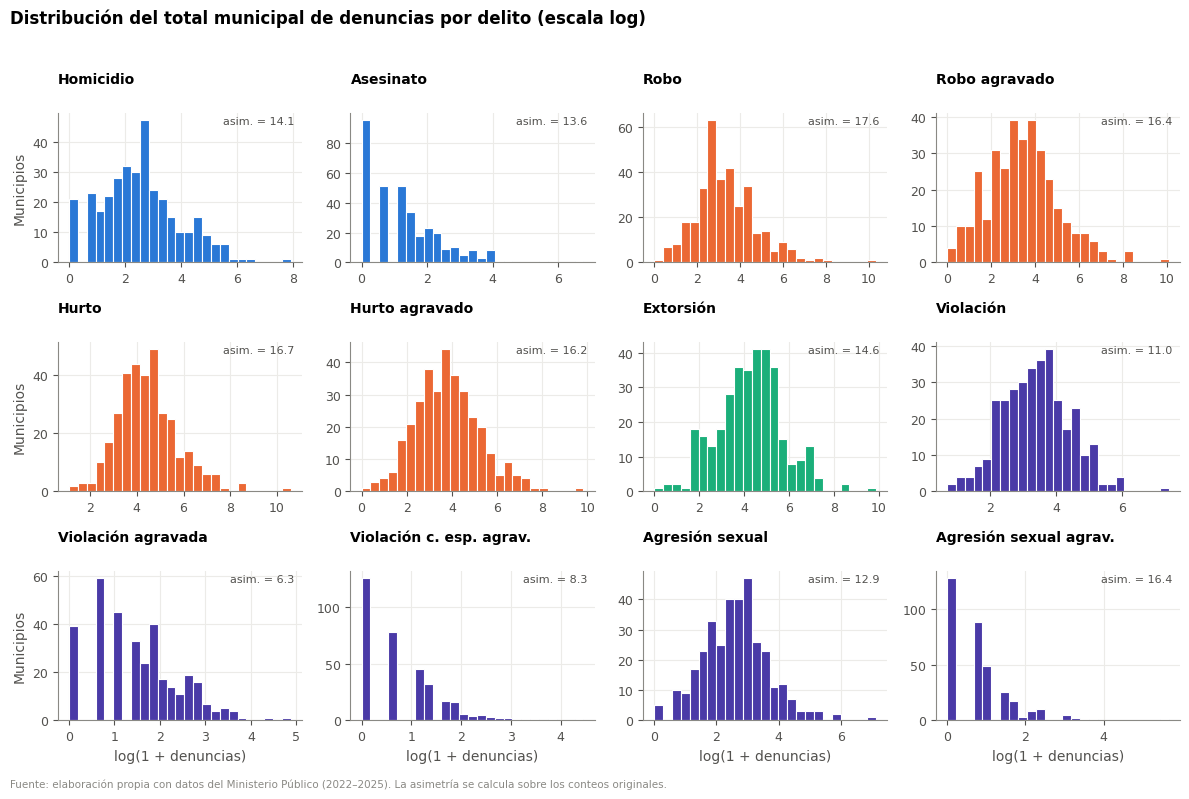

In [21]:
fig, axes = plt.subplots(3, 4, figsize=(12, 8))
for ax, delito in zip(axes.flat, ORDEN_DELITOS):
    x = np.log1p(mun_delito[delito])
    ax.hist(x, bins=25, color=COLOR_FAMILIA[FAMILIA_DELITO[delito]],
            edgecolor="white", linewidth=0.8)
    ax.set_title(NOMBRE_CORTO[delito], fontsize=10)
    ax.text(0.97, 0.93, f"asim. = {stats.skew(mun_delito[delito]):.1f}",
            transform=ax.transAxes, ha="right", fontsize=8, color=COLOR["texto_sec"])
for ax in axes[-1]:
    ax.set_xlabel("log(1 + denuncias)")
for ax in axes[:, 0]:
    ax.set_ylabel("Municipios")
fig.suptitle("Distribución del total municipal de denuncias por delito (escala log)",
             x=0.01, ha="left", fontweight="bold", fontsize=12)
fuente(fig, FUENTE_MP + " La asimetría se calcula sobre los conteos originales.")
fig.tight_layout(rect=(0, 0.02, 1, 0.96))
guardar_figura(fig, "09_histogramas_conteos_por_delito", CARPETA_FIG)
plt.show()

Aun en escala logarítmica las distribuciones son asimétricas y varios delitos (sobre todo los sexuales agravados) tienen una masa importante en cero. En escala original la asimetría es extrema, dominada por el municipio de Guatemala.

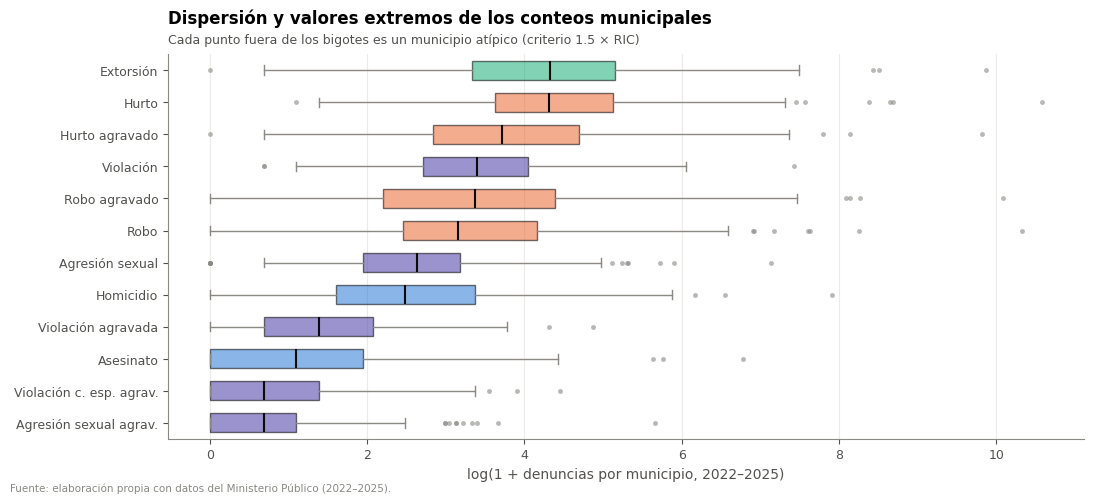

In [22]:
fig, ax = plt.subplots(figsize=(11, 5))
orden_box = mun_delito.median().sort_values().index
datos_box = [np.log1p(mun_delito[d]) for d in orden_box]
bp = ax.boxplot(datos_box, vert=False, patch_artist=True, widths=0.6,
                medianprops=dict(color=COLOR["texto"], linewidth=1.5),
                flierprops=dict(marker="o", markersize=3.5, markerfacecolor=COLOR["gris"],
                                markeredgecolor="none", alpha=0.6),
                whiskerprops=dict(color=COLOR["gris"]), capprops=dict(color=COLOR["gris"]))
for caja, d in zip(bp["boxes"], orden_box):
    caja.set_facecolor(COLOR_FAMILIA[FAMILIA_DELITO[d]])
    caja.set_alpha(0.55)
ax.set_yticks(range(1, len(orden_box) + 1), [NOMBRE_CORTO[d] for d in orden_box])
ax.set_xlabel("log(1 + denuncias por municipio, 2022–2025)")
ax.grid(axis="y", visible=False)
ax.set_title("Dispersión y valores extremos de los conteos municipales")
subtitulo(ax, "Cada punto fuera de los bigotes es un municipio atípico (criterio 1.5 × RIC)")
fuente(fig, FUENTE_MP)
fig.tight_layout()
guardar_figura(fig, "10_boxplot_conteos_por_delito", CARPETA_FIG)
plt.show()

## 9. Correlación entre delitos (conteos)

Se usa la **correlación de Spearman** (por rangos) porque las variables son muy asimétricas y tienen valores extremos; Pearson se vería dominado por unos pocos municipios grandes.

> **Advertencia:** en conteos absolutos casi todo se correlaciona positivamente porque **todos los delitos crecen con la población** (efecto tamaño). En el notebook 03 se repite el análisis con tasas para ver la relación real entre delitos.

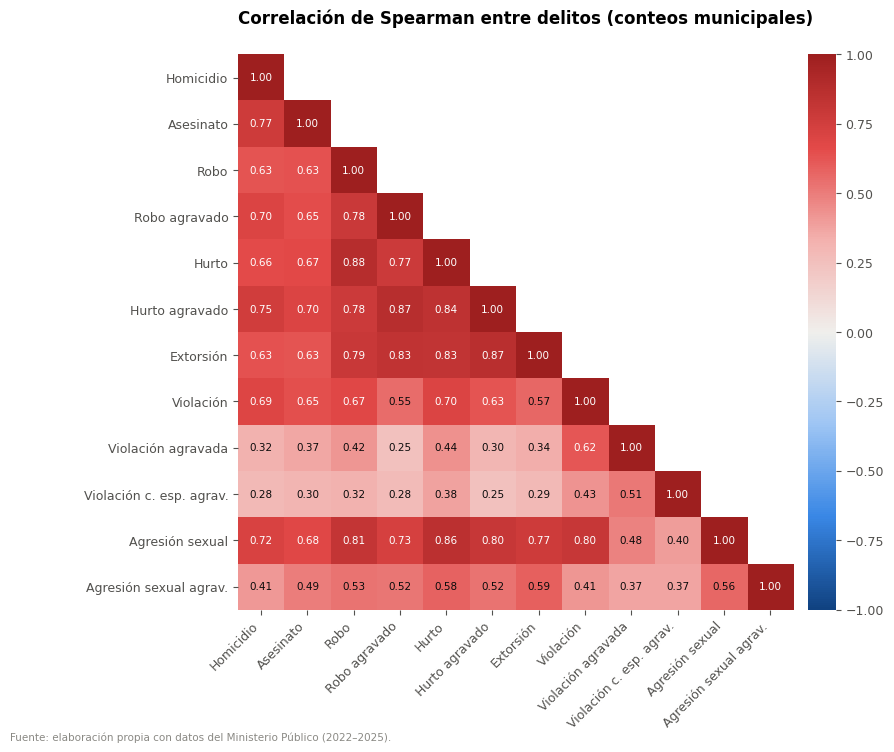

Correlación mínima fuera de la diagonal: 0.25
Correlación mediana fuera de la diagonal: 0.63


In [23]:
corr_conteos = mun_delito.rename(columns=NOMBRE_CORTO).corr(method="spearman")

fig, ax = plt.subplots(figsize=(9, 7.5))
mascara = np.triu(np.ones_like(corr_conteos, dtype=bool), k=1)
datos = np.ma.masked_where(mascara, corr_conteos.values)
im = ax.imshow(datos, cmap=CMAP_DIVERGENTE, vmin=-1, vmax=1)
n = len(corr_conteos)
ax.set_xticks(range(n), corr_conteos.columns, rotation=45, ha="right")
ax.set_yticks(range(n), corr_conteos.index)
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
for i in range(n):
    for j in range(i + 1):
        v = corr_conteos.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7.5,
                color="white" if abs(v) > 0.6 else COLOR["texto"])
ax.set_title("Correlación de Spearman entre delitos (conteos municipales)")
fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02).outline.set_visible(False)
fuente(fig, FUENTE_MP)
fig.tight_layout()
guardar_figura(fig, "11_correlacion_conteos", CARPETA_FIG)
plt.show()

print(f"Correlación mínima fuera de la diagonal: {corr_conteos.values[np.tril_indices(n, -1)].min():.2f}")
print(f"Correlación mediana fuera de la diagonal: {np.median(corr_conteos.values[np.tril_indices(n, -1)]):.2f}")

## 10. Exportación para la integración

Se guarda la tabla **municipio × año × delito** (grados sumados, ceros explícitos). Es la entrada del notebook 03.

In [24]:
anual_mun = (mensual.groupby(["Departamento", "Municipio", "Municipio_ID", "Anio", "Delito"],
                             as_index=False)["Denuncias"].sum())
anual_mun["Codigo_Delito"] = anual_mun["Delito"].map(DELITOS)

RUTA_PROCESSED.mkdir(parents=True, exist_ok=True)
ruta_salida = RUTA_PROCESSED / "denuncias_municipio_anio_delito.csv"
anual_mun.to_csv(ruta_salida, index=False, encoding="utf-8-sig")

assert len(anual_mun) == 340 * 4 * 12
assert anual_mun["Denuncias"].sum() == df_original["Denuncias"].sum()
print(f"Guardado: {ruta_salida.relative_to(RAIZ)}  ({len(anual_mun):,} filas)")

Guardado: data/processed/denuncias_municipio_anio_delito.csv  (16,320 filas)
